# Praktikum 3


## Pembuatan Dataset Sintetis


In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder

df = pd.read_csv('burnout_dataset1.csv')
df.fillna(df.mean(numeric_only=True), inplace=True)

# Mengambil sampel data agar komputasi efisien dan representatif
df_sample = df.sample(n=1000, random_state=42)

features = ['Work_Hours_Per_Week', 'Burnout_Score']
X = df_sample[features].values
labels_true = LabelEncoder().fit_transform(df_sample['Burnout_Risk'])

X = StandardScaler().fit_transform(X)


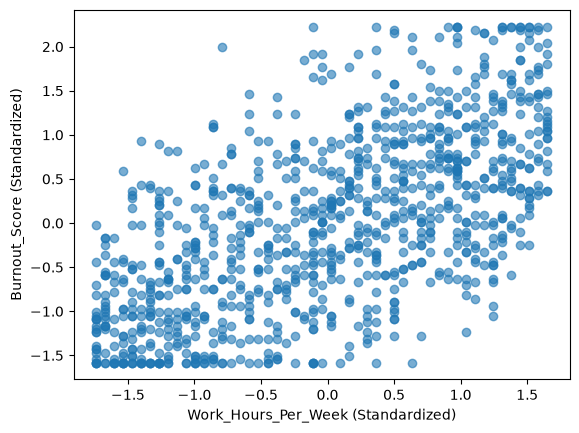

In [2]:
# Visualisasikan data
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], alpha=0.6)
plt.xlabel('Work_Hours_Per_Week (Standardized)')
plt.ylabel('Burnout_Score (Standardized)')
plt.show()


## Compute DBSCAN


In [3]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)


Estimated number of clusters: 1
Estimated number of noise points: 22


## Evaluasi Kualitas Klasterisasi


In [4]:
print("Homogeneity: %0.3f" % metrics.homogeneity_score(labels_true, labels))
print("Completeness: %0.3f" % metrics.completeness_score(labels_true, labels))
print("V-measure: %0.3f" % metrics.v_measure_score(labels_true, labels))
print("Adjusted Rand Index: %0.3f" % metrics.adjusted_rand_score(labels_true, labels))
print(
    "Adjusted Mutual Information: %0.3f"
    % metrics.adjusted_mutual_info_score(labels_true, labels)
)
print("Silhouette Coefficient: %0.3f" % metrics.silhouette_score(X, labels))


Homogeneity: 0.026
Completeness: 0.252
V-measure: 0.046
Adjusted Rand Index: 0.021
Adjusted Mutual Information: 0.045
Silhouette Coefficient: 0.173


## Visualisasi Hasil Klasterisasi


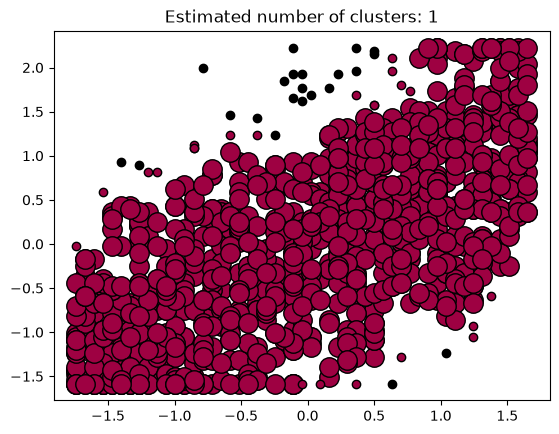

In [5]:
# Visualisasi Hasil Klasterisasi
import matplotlib.pyplot as plt
import numpy as np

# Menentukan warna unik untuk setiap cluster
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    # Plot core samples (titik besar)
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    # Plot non-core samples (titik kecil)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title("Estimated number of clusters: %d" % n_clusters_)
plt.show()
